# Análisis exploratorio con el dataset final
Ciencia de Datos · UTN FRM · 2026

**La pregunta del proyecto:** cuando ocurre un sismo, ¿cuántas réplicas podemos esperar?

Este notebook repite el análisis exploratorio de la Entrega 2 sobre el **dataset final**, el mismo que usan el modelo de la Entrega 3 y la aplicación:
cinco regiones, `mainshock = root` (el principal es el sismo que abre la secuencia) y tope de distancia `rmax = gk3`.

El notebook de la Entrega 2 (`Análisis Exploratorio de Sismos (clusters).ipynb`) se hizo sobre otro dataset —sólo los Andes centrales, 2016–2026,
`mainshock = largest`, 1.978 secuencias y 15 columnas— y queda como estaba. Las medidas y el semáforo son los mismos de aquel notebook.

## El dataset

In [1]:
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", None)

DATOS = "../data/"
ARCHIVO = DATOS + "clusters_combined_5regions_rmax=gk3_mainshock=root_seed=1.csv"
df = pd.read_csv(ARCHIVO, low_memory=False)
df["mainshock_time"] = pd.to_datetime(df["mainshock_time"])
df.shape

(21292, 27)

In [2]:
# Las mismas medidas y el mismo semáforo del notebook de la Entrega 2
def separacion(x, y):
    """Distancia entre dos muestras, en desviaciones estándar."""
    x, y = x.dropna(), y.dropna()
    return abs(x.mean() - y.mean()) / np.sqrt((x.std() ** 2 + y.std() ** 2) / 2)

def eta2(numerica, categoria):
    """Proporción de la varianza de la numérica que explica la categoría."""
    g = numerica.groupby(categoria, observed=True)
    m = numerica.mean()
    return (g.count() * (g.mean() - m) ** 2).sum() / ((numerica - m) ** 2).sum()

def asociacion(x, y):
    """Pearson, Spearman y la brecha entre ambos."""
    p, s = x.corr(y), x.corr(y, method="spearman")
    return pd.Series({"pearson": p, "spearman": s, "brecha": s - p}).round(3)

CORTES = {"separacion": (0.2, 0.8), "eta2": (0.05, 0.25), "correlacion": (0.2, 0.6), "brecha": (0.05, 0.15)}

def semaforo(valor, medida):
    bajo, alto = CORTES[medida]
    v = abs(valor)
    return "rojo" if v < bajo else "verde" if v > alto else "amarillo"

## Las 27 columnas

In [3]:
pd.DataFrame({"tipo": df.dtypes.astype(str), "valores distintos": df.nunique(),
              "nulos (%)": (df.isna().mean() * 100).round(1)})

,tipo,valores distintos,nulos (%)
cluster_id,str,21292,0.0
mainshock_id,str,21292,0.0
mainshock_place,str,17662,0.0
mainshock_mag,float64,43,0.0
mainshock_time,"datetime64[us, UTC]",21292,0.0
mainshock_lat,float64,19810,0.0
mainshock_lon,float64,20094,0.0
mainshock_depth,float64,8646,0.0
n_events,int64,69,0.0
n_aftershocks,int64,69,0.0


Los únicos nulos son estructurales: `prior_max_mag_365d` (5,9 %) no tiene valor cuando no hubo sismos previos en el último año, y `days_since_prior` (1,5 %)
cuando no hubo ninguno desde el comienzo del catálogo.

Separamos las columnas según **cuándo se conoce su valor**. El instante de la predicción es el momento del sismo principal: una columna sólo puede entrar al
modelo si existe en ese instante.

- **Identifica la secuencia:** las claves y el texto del lugar, y la fecha, que sirve para ordenar y partir en entrenamiento y test, no como entrada.
- **Es la respuesta:** `n_aftershocks` y su versión sí/no, `has_aftershock`.
- **Fuga:** describen la secuencia ya terminada (cuántos eventos tuvo, cuánto duró, hasta dónde llegó, cuántas generaciones de réplicas hubo).
- **Constante con `mainshock = root`:** no varían en este dataset.
- **Existe al predecir:** el sismo principal (magnitud, profundidad, posición), la región y sus parámetros, la sismicidad previa y la cercanía al borde de la región.

In [4]:
# Cada columna en un solo grupo (el criterio de cada grupo está en el markdown de arriba)
GRUPOS = {
    "identifica la secuencia": ["cluster_id", "mainshock_id", "mainshock_place", "mainshock_time"],
    "es la respuesta": ["n_aftershocks", "has_aftershock"],
    "fuga: se sabe cuando la secuencia terminó": ["n_events", "duration_days", "extent_km", "max_generation"],
    "constante con mainshock = root": ["n_foreshocks", "root_is_mainshock"],
    "existe al predecir": ["mainshock_mag", "mainshock_depth", "mainshock_lat", "mainshock_lon", "region", "region_mc",
                            "region_log10_eta0", "n_prior_2d", "n_prior_30d", "n_prior_365d", "prior_max_mag_365d",
                            "days_since_prior", "prior_window_truncated", "dist_to_border_km", "near_border"],
}
asignadas = [c for cols in GRUPOS.values() for c in cols]
assert sorted(asignadas) == sorted(df.columns), "cada columna tiene que estar en un grupo, y una sola vez"
pd.Series({g: len(c) for g, c in GRUPOS.items()}, name="columnas").to_frame().assign(
    **{"total": lambda t: t["columnas"].sum()})

,columnas,total
identifica la secuencia,4,27
es la respuesta,2,27
fuga: se sabe cuando la secuencia terminó,4,27
constante con mainshock = root,2,27
existe al predecir,15,27


4 + 2 + 4 + 2 + 15 = 27. De las 27 columnas, **15 existen en el momento del sismo**.

In [5]:
df[GRUPOS["constante con mainshock = root"]].nunique()

n_foreshocks         1
root_is_mainshock    1
dtype: int64

`n_foreshocks` vale siempre 0 y `root_is_mainshock` siempre verdadero: con `mainshock = root` el principal es el primer evento de la secuencia, así que
no puede haber premonitores antes que él. En el dataset de la Entrega 2 (`largest`) sí variaban, y ahí eran fuga: un premonitor se reconoce recién cuando
llega el sismo mayor.

In [6]:
# n_events es la respuesta más uno: con root el principal es el primer evento y no hay premonitores
pd.Series({"filas donde n_events == n_aftershocks + 1 (%)": (df["n_events"] == df["n_aftershocks"] + 1).mean() * 100,
           "correlación n_events con n_aftershocks": df["n_events"].corr(df["n_aftershocks"])}).round(3)

filas donde n_events == n_aftershocks + 1 (%)    100.0
correlación n_events con n_aftershocks             1.0
dtype: float64

`n_events` es exactamente `n_aftershocks + 1` en todas las filas: es la respuesta disfrazada.

## La respuesta: `n_aftershocks`

In [7]:
y = df["n_aftershocks"]
pd.Series({"secuencias": len(df), "réplicas totales": int(y.sum()), "sin réplicas (%)": (y == 0).mean() * 100,
           "media": y.mean(), "varianza": y.var(), "varianza / media": y.var() / y.mean(),
           "mediana": y.median(), "máximo": y.max()}).round(2)

secuencias          21292.00
réplicas totales    16221.00
sin réplicas (%)       88.08
media                   0.76
varianza              496.79
varianza / media      652.10
mediana                 0.00
máximo               2544.00
dtype: float64

In [8]:
CLASES = ["ninguna (0)", "pocas (1–2)", "moderadas (3–10)", "muchas (11+)"]
clase = pd.cut(y, [-1, 0, 2, 10, np.inf], labels=CLASES)
clase.value_counts().reindex(CLASES).to_frame("secuencias").assign(**{"%": lambda t: (t["secuencias"] / len(y) * 100).round(1)})

,secuencias,%
n_aftershocks,,
ninguna (0),18753,88.1
pocas (1–2),1920,9.0
moderadas (3–10),477,2.2
muchas (11+),142,0.7


El 88,1 % de las secuencias no tiene ninguna réplica, la mediana es 0 y el máximo, 2.544. La varianza es 652 veces la media (en el dataset de la
Entrega 2 era 9 veces).

## Las cinco regiones

In [9]:
df.groupby("region").agg(secuencias=("n_aftershocks", "size"), mc=("region_mc", "first"),
                         desde=("mainshock_time", "min"), hasta=("mainshock_time", "max"),
                         sin_replicas_pct=("n_aftershocks", lambda s: round((s == 0).mean() * 100, 1)),
                         m6_o_mas=("mainshock_mag", lambda s: int((s >= 6).sum())))

,secuencias,mc,desde,hasta,sin_replicas_pct,m6_o_mas
region,,,,,,
andes,4423,4.5,2008-01-01 23:07:00+00:00,2025-12-30 20:26:04+00:00,93.2,102
japan,4246,4.6,2003-01-05 09:50:51+00:00,2025-12-31 14:26:57+00:00,89.7,115
mexico_ca,6507,4.2,2003-01-01 00:18:43+00:00,2025-12-28 09:55:25+00:00,83.9,95
philippines,2169,4.7,2003-01-02 05:01:56+00:00,2025-12-27 18:26:23+00:00,87.1,77
sumatra_java,3947,4.6,2003-01-03 08:19:50+00:00,2025-12-30 13:43:09+00:00,87.9,101


## Casos atípicos

Con `mainshock = root` todas las réplicas de la secuencia se le cuentan al sismo que la abre, aunque después haya venido uno más grande. Para ver cuánto
pasa eso cruzamos cada secuencia con sus eventos y tomamos su magnitud máxima.

In [10]:
# La magnitud mayor de cada secuencia sale de los eventos (un archivo por región)
eventos = pd.concat([pd.read_csv(f, usecols=["id", "mag", "cluster_id"])
                     for f in sorted(glob.glob(DATOS + "events_*rmax=gk3_mainshock=root_seed=1.csv"))])
df = df.merge(eventos.groupby("cluster_id")["mag"].max().rename("mag_maxima"), left_on="cluster_id", right_index=True, how="left")
df["mag_sobre_mc"] = df["mainshock_mag"] - df["region_mc"]
df["vino_uno_mayor"] = df["mag_maxima"] > df["mainshock_mag"] + 1e-9
pd.Series({"secuencias sin magnitud máxima (no cruzaron)": int(df["mag_maxima"].isna().sum()),
           "secuencias donde después vino un sismo mayor que el principal": int(df["vino_uno_mayor"].sum()),
           "% de las secuencias": round(df["vino_uno_mayor"].mean() * 100, 1),
           "% de todas las réplicas que suman esas secuencias": round(df.loc[df["vino_uno_mayor"], "n_aftershocks"].sum() / y.sum() * 100, 1)})

secuencias sin magnitud máxima (no cruzaron)                       0.0
secuencias donde después vino un sismo mayor que el principal    819.0
% de las secuencias                                                3.8
% de todas las réplicas que suman esas secuencias                 42.3
dtype: float64

En 819 secuencias (3,8 %) vino después un sismo mayor que el principal, y esas secuencias suman el **42,3 % de todas las réplicas** del dataset.

In [11]:
COLS = ["mainshock_time", "mainshock_place", "region", "mainshock_mag", "mag_maxima", "mainshock_depth", "n_aftershocks"]
df.nlargest(10, "n_aftershocks")[COLS]

,mainshock_time,mainshock_place,region,mainshock_mag,mag_maxima,mainshock_depth,n_aftershocks
4423,2011-03-09 02:45:20+00:00,"120 km SE of ?funato, Japan",japan,7.3,9.1,32.00,2544
10838,2004-12-26 00:58:53+00:00,2004 Sumatra - Andaman Islands Earthquake,sumatra_java,9.1,9.1,30.00,1361
0,2010-02-27 06:34:11+00:00,"2010 Maule, Chile Earthquake",andes,8.8,8.8,22.90,1045
14785,2017-09-07 07:05:26+00:00,"103 km SW of El Palmarcito, Mexico",mexico_ca,4.4,8.2,35.34,555
1,2015-09-16 22:54:32+00:00,"48 km W of Illapel, Chile",andes,8.3,8.3,22.44,379
8669,2023-12-02 14:37:04+00:00,"19 km E of Gamut, Philippines",philippines,7.6,7.6,40.00,322
10839,2005-01-26 17:30:28+00:00,"296 km NNW of Sabang, Indonesia",sumatra_java,5.6,5.9,23.30,321
10840,2007-09-12 11:10:26+00:00,"122 km SW of Bengkulu, Indonesia",sumatra_java,8.4,8.4,34.00,303
10841,2006-07-17 08:19:26+00:00,"226 km SSW of Singaparna, Indonesia",sumatra_java,7.7,7.7,20.00,240
2,2014-04-01 23:46:47+00:00,"93 km NW of Iquique, Chile",andes,8.2,8.2,25.00,216


Las diez secuencias con más réplicas. La primera abre con un M7,3 frente a Ōfunato (Japón) el 9 de marzo de 2011, y la magnitud máxima de esa
secuencia es 9,1. La cuarta abre con un M4,4 frente a El Palmarcito (México) el 7 de septiembre de 2017, y su máxima es 8,2.

In [12]:
# Principales que apenas superan el umbral de su región y que tuvieron más de 10 réplicas
chicos = df[(df["mag_sobre_mc"] < 0.5) & (df["n_aftershocks"] > 10)]
print(len(chicos), "secuencias; en", int(chicos["vino_uno_mayor"].sum()), "vino después un sismo mayor que el principal")
chicos.sort_values("n_aftershocks", ascending=False)[COLS]

25 secuencias; en 25 vino después un sismo mayor que el principal


,mainshock_time,mainshock_place,region,mainshock_mag,mag_maxima,mainshock_depth,n_aftershocks
14785,2017-09-07 07:05:26+00:00,"103 km SW of El Palmarcito, Mexico",mexico_ca,4.4,8.2,35.340,555
8671,2019-10-11 01:55:07+00:00,"9 km NE of Telafas, Philippines",philippines,5.1,6.8,10.000,69
10846,2006-03-09 14:47:56+00:00,"220 km ESE of Port Blair, India",sumatra_java,4.7,5.4,19.900,62
4426,2011-08-08 07:19:57+00:00,"36 km E of Namie, Japan",japan,4.6,6.9,59.000,50
4,2017-04-22 22:46:42+00:00,"48 km W of Valparaíso, Chile",andes,4.9,6.9,9.440,42
10850,2019-03-31 23:42:01+00:00,"211 km NNW of Sabang, Indonesia",sumatra_java,5.0,5.5,10.000,39
8675,2011-07-10 16:42:57+00:00,"24 km SW of Cayhagan, Philippines",philippines,5.0,6.4,10.000,36
10851,2015-11-08 09:51:51+00:00,"142 km NNW of Sabang, Indonesia",sumatra_java,4.6,6.6,19.560,35
10854,2009-07-26 06:45:35+00:00,"206 km ESE of Port Blair, India",sumatra_java,4.8,5.2,10.000,31
10855,2022-07-04 05:35:51+00:00,"204 km SE of Port Blair, India",sumatra_java,4.7,5.4,10.000,28


Los 25 principales que superan el umbral de su región por menos de medio punto y tuvieron más de 10 réplicas comparten algo: **en los 25 vino
después un sismo mayor que el principal**. En el notebook de la Entrega 3 (análisis de errores del test) esto había quedado como una posibilidad sin
comprobar, porque faltaba la magnitud máxima de cada secuencia.

In [13]:
# Principales de M7 o más con 2 réplicas o menos
grandes_pocas = df[(df["mainshock_mag"] >= 7) & (df["n_aftershocks"] <= 2)]
print(len(grandes_pocas), "secuencias;", int((grandes_pocas["mainshock_depth"] > 300).sum()), "a más de 300 km de profundidad")
grandes_pocas[COLS]

7 secuencias; 5 a más de 300 km de profundidad


,mainshock_time,mainshock_place,region,mainshock_mag,mag_maxima,mainshock_depth,n_aftershocks
270,2011-01-01 09:56:58+00:00,"26 km NNE of El Hoyo, Argentina",andes,7.0,7.0,576.800,1
4578,2009-08-09 10:55:55+00:00,"161 km S of ?yama, Japan",japan,7.1,7.1,292.000,2
8919,2024-07-11 02:13:18+00:00,"106 km WSW of Sangay, Philippines",philippines,7.1,7.1,639.503,1
8930,2005-02-05 12:23:18+00:00,"138 km SW of Palimbang, Philippines",philippines,7.1,7.1,525.000,1
11016,2023-04-14 09:55:45+00:00,"Java, Indonesia",sumatra_java,7.0,7.0,597.000,2
13246,2004-07-25 14:35:19+00:00,"100 km SSE of Jambi City, Indonesia",sumatra_java,7.3,7.3,582.100,0
15479,2017-09-19 18:14:38+00:00,"1 km S of Matzaco, Mexico",mexico_ca,7.1,7.1,48.000,1


7 principales de M7 o más tuvieron 2 réplicas o menos. 5 están a más de 300 km de profundidad, uno a 292 km y uno a 48 km.

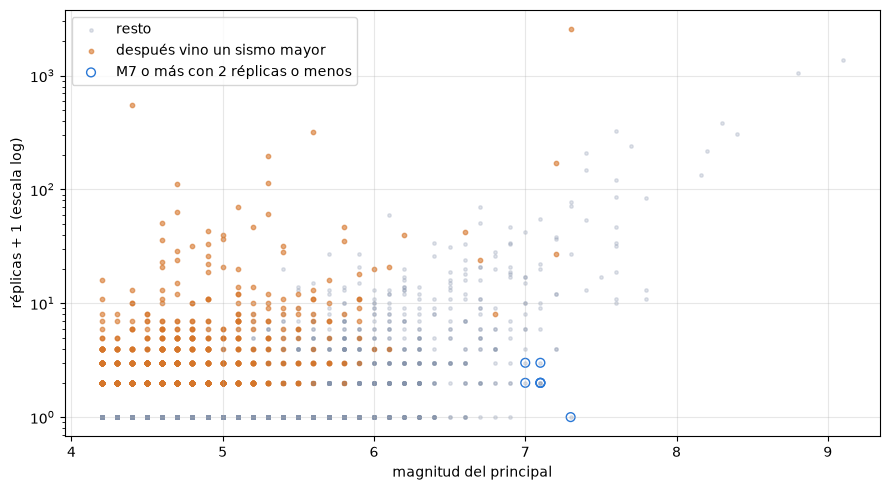

In [14]:
fig, ax = plt.subplots(figsize=(9, 5))
base = df[~df["vino_uno_mayor"]]
ax.scatter(base["mainshock_mag"], base["n_aftershocks"] + 1, s=6, alpha=0.25, color="#8593ab", label="resto")
ax.scatter(df.loc[df["vino_uno_mayor"], "mainshock_mag"], df.loc[df["vino_uno_mayor"], "n_aftershocks"] + 1, s=10,
           alpha=0.6, color="#d6762a", label="después vino un sismo mayor")
ax.scatter(grandes_pocas["mainshock_mag"], grandes_pocas["n_aftershocks"] + 1, s=40, facecolors="none",
           edgecolors="#2a78d6", label="M7 o más con 2 réplicas o menos")
ax.set_yscale("log"); ax.set_xlabel("magnitud del principal"); ax.set_ylabel("réplicas + 1 (escala log)")
ax.legend(); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

## Hipótesis 1 · Las réplicas crecen con la magnitud

La misma medida de la Entrega 2: η² de las réplicas entre tramos de magnitud.

In [15]:
tramo = pd.cut(df["mainshock_mag"], [4, 5, 6, 7, 10], labels=["4–5", "5–6", "6–7", "7 o más"], right=False)
e1 = eta2(y, tramo)
print("η² =", round(e1, 3), semaforo(e1, "eta2"))
df.groupby(tramo, observed=True)["n_aftershocks"].agg(secuencias="size", media="mean", maximo="max").round(2)

η² = 0.106 amarillo


,secuencias,media,maximo
mainshock_mag,,,
4–5,16232,0.19,555
5–6,4570,0.70,321
6–7,431,4.26,69
7 o más,59,138.24,2544


η² = 0,106 (amarillo). En la Entrega 2, con el otro dataset, había dado 0,377.

In [16]:
# El mismo análisis con la magnitud sobre el umbral de la región, en tramos de 0,5 con al menos 10 secuencias
t = df.assign(tramo=np.floor((df["mag_sobre_mc"] + 1e-9) / 0.5) * 0.5).groupby("tramo")["n_aftershocks"].agg(
    secuencias="size", media="mean")
t = t[t["secuencias"] >= 10]
t["multiplica al anterior"] = (t["media"] / t["media"].shift()).round(1)
t.round(2)

,secuencias,media,multiplica al anterior
tramo,,,
0.0,16410,0.18,NaN
0.5,3420,0.50,2.8
1.0,955,1.45,2.9
1.5,334,2.93,2.0
2.0,121,8.64,2.9
2.5,28,127.82,14.8
3.0,18,62.00,0.5


Con la magnitud sobre el umbral de la región, de +0 a +2,0 las réplicas medias se multiplican por entre 2,0 y 2,9 en cada medio punto. El salto
de +2,0 a +2,5 es de 14,8, y el último tramo (+3,0, 18 secuencias) baja.

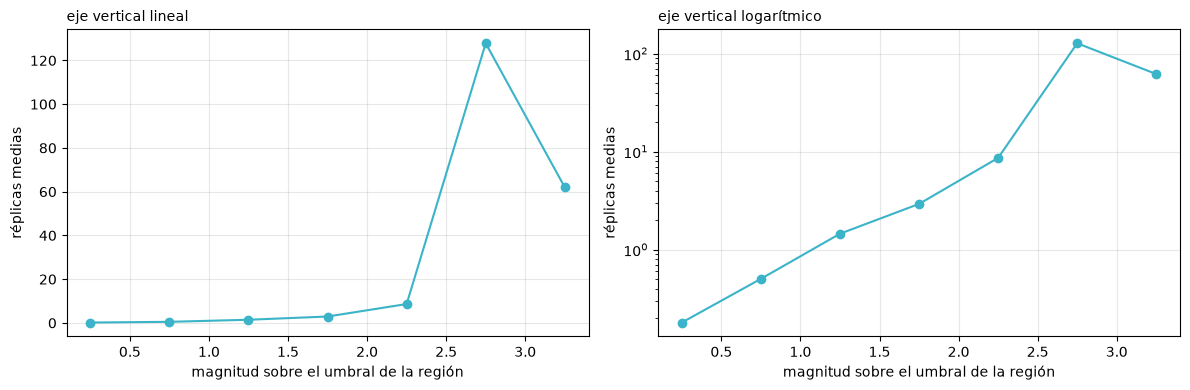

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, escala in zip(axes, ["linear", "log"]):
    ax.plot(t.index + 0.25, t["media"], "o-", color="#3bb3c8")
    ax.set_yscale(escala); ax.grid(alpha=0.3)
    ax.set_xlabel("magnitud sobre el umbral de la región"); ax.set_ylabel("réplicas medias")
    ax.set_title("eje vertical lineal" if escala == "linear" else "eje vertical logarítmico", loc="left", fontsize=10)
plt.tight_layout(); plt.show()

Los mismos puntos con dos ejes verticales. Con el lineal, la curva queda casi plana hasta +2 y sube de golpe al final. Con el logarítmico, los
tramos de +0 a +2,0 quedan casi alineados: un crecimiento por un factor parecido en cada tramo.

## Hipótesis 3 · Los sismos someros dejan más réplicas que los profundos

La misma comparación de la Entrega 2: separación estandarizada entre someros (menos de 70 km) y el resto, η² con tres franjas y, después, sólo los
sismos grandes.

In [18]:
prof = df["mainshock_depth"]
pd.Series({"menos de 70 km (%)": (prof < 70).mean() * 100, "exactamente 10 km (%)": (prof == 10).mean() * 100,
           "mediana (km)": prof.median(), "percentil 25 (km)": prof.quantile(0.25), "percentil 75 (km)": prof.quantile(0.75),
           "percentil 95 (km)": prof.quantile(0.95), "máxima (km)": prof.max()}).round(1)

menos de 70 km (%)        70.3
exactamente 10 km (%)     13.0
mediana (km)              41.9
percentil 25 (km)         22.0
percentil 75 (km)         82.5
percentil 95 (km)        191.8
máxima (km)              650.7
dtype: float64

El 70,3 % de los principales está a menos de 70 km, y la mitad del dataset cae entre 22 y 82,5 km. El 13 % tiene exactamente 10 km de profundidad.

In [19]:
someros, resto = y[prof < 70], y[prof >= 70]
s = separacion(someros, resto)
print("separación someros (<70 km) contra el resto:", round(s, 3), semaforo(s, "separacion"))
franja = pd.cut(prof, [-1, 70, 300, 800], labels=["superficial (<70 km)", "intermedio (70-300 km)", "profundo (>300 km)"])
e3 = eta2(y, franja)
print("η² con tres franjas:", round(e3, 4), semaforo(e3, "eta2"))
df.groupby(franja, observed=True).agg(secuencias=("n_aftershocks", "size"), media=("n_aftershocks", "mean"),
                                       con_al_menos_una=("n_aftershocks", lambda s: (s > 0).mean()),
                                       mag_media=("mainshock_mag", "mean")).round(3)

separación someros (<70 km) contra el resto: 0.051 rojo
η² con tres franjas: 0.0004 rojo


,secuencias,media,con_al_menos_una,mag_media
mainshock_depth,,,,
superficial (<70 km),14980,1.043,0.148,4.790
intermedio (70-300 km),5961,0.087,0.050,4.727
profundo (>300 km),351,0.219,0.066,5.163


Separación 0,051 y η² 0,0004: los dos en rojo. Las medias por franja son 1,04, 0,09 y 0,22 réplicas, y el porcentaje de secuencias con al menos
una réplica, 14,8 %, 5,0 % y 6,6 %.

In [20]:
m6 = df[df["mainshock_mag"] >= 6]
s6 = separacion(m6.loc[m6["mainshock_depth"] < 70, "n_aftershocks"], m6.loc[m6["mainshock_depth"] >= 70, "n_aftershocks"])
print("separación someros contra el resto, sólo M6 o más:", round(s6, 3), semaforo(s6, "separacion"))
m6.groupby(m6["mainshock_depth"] < 70)["n_aftershocks"].agg(secuencias="size", media="mean", mediana="median",
                                                            maximo="max").rename(index={True: "someros", False: "70 km o más"}).round(2)

separación someros contra el resto, sólo M6 o más: 0.216 amarillo


,secuencias,media,mediana,maximo
mainshock_depth,,,,
70 km o más,126,1.78,1.0,41
someros,364,26.84,3.0,2544


Sólo con M6 o más, la separación sube a 0,216 (amarillo): 364 someros con media 26,8 y mediana 3, contra 126 de 70 km o más con media 1,78 y
mediana 1.

In [21]:
pd.Series({"correlación magnitud-profundidad": df["mainshock_mag"].corr(prof),
           "spearman magnitud-profundidad": df["mainshock_mag"].corr(prof, method="spearman")}).round(3)

correlación magnitud-profundidad    0.044
spearman magnitud-profundidad      -0.016
dtype: float64

Magnitud y profundidad casi no están correlacionadas (Pearson 0,044, Spearman −0,016).

## Hipótesis 4 · Con la magnitud alcanza para saber cuántas réplicas habrá

In [22]:
h4 = asociacion(m6["mainshock_mag"], m6["n_aftershocks"])
someros6 = m6[m6["mainshock_depth"] < 70]
h4s = asociacion(someros6["mainshock_mag"], someros6["n_aftershocks"])
pd.DataFrame({"M6 o más": [len(m6), h4["pearson"], h4["spearman"], m6["n_aftershocks"].std() / m6["n_aftershocks"].mean(),
                           m6["n_aftershocks"].min(), m6["n_aftershocks"].max()],
              "M6 o más, someros": [len(someros6), h4s["pearson"], h4s["spearman"],
                                    someros6["n_aftershocks"].std() / someros6["n_aftershocks"].mean(),
                                    someros6["n_aftershocks"].min(), someros6["n_aftershocks"].max()]},
             index=["secuencias", "pearson", "spearman", "coef. de variación", "mínimo", "máximo"]).round(3)

,M6 o más,"M6 o más, someros"
secuencias,490.000,364.000
pearson,0.392,0.415
spearman,0.504,0.590
coef. de variación,6.964,6.123
mínimo,0.000,0.000
máximo,2544.000,2544.000


Entre los 490 sismos de M6 o más: Pearson 0,392 y Spearman 0,504, con réplicas de 0 a 2.544 y un coeficiente de variación de 7,0. Sólo con los
someros, Pearson 0,415 y Spearman 0,590. En la Entrega 2 había dado Pearson 0,43.

## Las 15 columnas que existen al predecir

In [23]:
# Asociación con el objetivo de cada columna que existe al predecir
numericas = ["mainshock_mag", "mainshock_depth", "mainshock_lat", "mainshock_lon", "region_mc", "region_log10_eta0",
             "n_prior_2d", "n_prior_30d", "n_prior_365d", "prior_max_mag_365d", "days_since_prior", "dist_to_border_km"]
tabla = pd.DataFrame({c: asociacion(df[c], y) for c in numericas}).T
tabla["zona (spearman)"] = [semaforo(v, "correlacion") for v in tabla["spearman"]]
tabla.sort_values("spearman", key=abs, ascending=False)

,pearson,spearman,brecha,zona (spearman)
mainshock_mag,0.149,0.214,0.065,amarillo
mainshock_depth,-0.015,-0.173,-0.158,rojo
region_log10_eta0,-0.003,0.088,0.091,rojo
mainshock_lon,0.007,-0.053,-0.060,rojo
days_since_prior,-0.001,-0.050,-0.048,rojo
n_prior_30d,0.005,0.049,0.044,rojo
n_prior_365d,-0.003,0.046,0.049,rojo
n_prior_2d,0.004,0.042,0.038,rojo
region_mc,0.005,-0.041,-0.046,rojo
mainshock_lat,0.005,0.039,0.035,rojo


In [24]:
categoricas = ["region", "near_border", "prior_window_truncated"]
pd.DataFrame({"η²": [eta2(y, df[c]) for c in categoricas]}, index=categoricas).assign(
    zona=lambda t: [semaforo(v, "eta2") for v in t["η²"]]).round(4)

,η²,zona
region,0.0001,rojo
near_border,0.0000,rojo
prior_window_truncated,0.0000,rojo


Con el semáforo de la Entrega 2 sólo la magnitud sale del rojo (Spearman 0,214, amarillo). La profundidad le sigue (−0,173). El resto queda por
debajo de 0,1 en valor absoluto, y región, cercanía al borde y ventana truncada tienen η² menor que 0,001.

## Qué columnas llegan al modelo

De las 15, la Entrega 3 probó cinco (`mainshock_mag`, `mainshock_depth`, `region_mc`, `region`, `n_prior_30d`). El modelo final usa **tres**: la magnitud
y el umbral de la región combinados en `mag_sobre_mc = mainshock_mag − region_mc`, y la profundidad. `region` y `n_prior_30d` se probaron y no mejoraron el
f1 macro por más que el desvío. La latitud y la longitud se habían descartado en el análisis de la Entrega 2 por su correlación casi nula con las réplicas (Pearson −0,034 y −0,063), y acá también quedan en rojo (Spearman 0,039 y −0,053). Las otras ocho no se probaron en la Entrega 3; se prueban en la sección siguiente.

## ¿Ayudan al modelo las columnas que no se probaron?

En la Entrega 3 se probaron sólo cinco columnas. Ocho de las que faltan no estaban en el dataset con el que se empezó a armar el modelo, y la
latitud y la longitud se habían descartado en el análisis exploratorio sólo por su correlación. Acá se prueban esas diez.

**Método:** el mismo de la Entrega 3 (celda 54). El Poisson con magnitud sobre el umbral y profundidad, agregando **una columna por vez**,
con validación temporal de 5 folds sobre el entrenamiento (el 80 % más viejo). El test no se usa: es para evaluar una sola vez, no para elegir.
Se mide en dos configuraciones: la de la celda 54 (alpha 1, empuje 0) y la del modelo elegido (alpha 0,001, empuje 0,4).

**Dos medidas:** el f1 macro, que es el criterio del proyecto (una columna sirve si mejora por más que el desvío), y la deviance de Poisson
media, más sensible para ver si una columna aporta información aunque no cambie la clase que contesta el modelo.

**¿Alguna es fuga?** No: todas existen en el momento del sismo.
- `n_prior_2d`, `n_prior_365d`, `prior_max_mag_365d` y `days_since_prior` se calculan con sismos **anteriores** al principal.
- `prior_window_truncated` dice si la ventana de un año empieza antes que el catálogo: no es fuga, pero describe el catálogo, no el sismo.
- `dist_to_border_km` y `near_border` miden la distancia al borde del rectángulo de la región: no son fuga, pero si ayudaran, el modelo
  aprendería un artefacto (réplicas que quedan afuera del rectángulo).
- `region_log10_eta0` vale lo mismo en toda la región (equivale a la columna `region`) y se estima con el catálogo completo, igual que
  `region_mc`, que el modelo ya usa: es un parámetro fijo de cada región.
- `mainshock_lat` y `mainshock_lon`: el epicentro, conocido en el momento.

In [25]:
import sys
import warnings
sys.path.insert(0, "..")                        # el modelo de la Entrega 3 tal cual (referencia_sklearn.py, en la raíz)
from referencia_sklearn import PoissonIntervalos, a_intervalo
from palette import CLASES
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.metrics import f1_score, mean_poisson_deviance
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
warnings.filterwarnings("ignore")

# la misma partición del modelo: orden cronológico, el 80 % más viejo entrena
orden = df.sort_values("mainshock_time").reset_index(drop=True)
tr = orden.iloc[:int(len(orden) * 0.8)].reset_index(drop=True)
y_tr = tr["n_aftershocks"]
cv = list(TimeSeriesSplit(n_splits=5).split(tr))
len(tr)

17033

In [26]:
def candidatas(X):
    """Cada columna, transformada como tiene sentido en una regresión con enlace log."""
    sobre_mc = X["prior_max_mag_365d"] - X["region_mc"]
    dias = X["days_since_prior"]
    return {
        "n_prior_30d": pd.DataFrame({"log_n_prior_30d": np.log1p(X["n_prior_30d"])}),     # la de la Entrega 3, de control
        "n_prior_2d": pd.DataFrame({"log_n_prior_2d": np.log1p(X["n_prior_2d"])}),
        "n_prior_365d": pd.DataFrame({"log_n_prior_365d": np.log1p(X["n_prior_365d"])}),
        "prior_max_mag_365d": pd.DataFrame({"prior_max_sobre_mc": sobre_mc.fillna(-0.5),    # sin previos: por debajo de todo
                                            "sin_previos_365d": sobre_mc.isna().astype(float)}),
        "days_since_prior": pd.DataFrame({"log_dias": np.log1p(dias.fillna(dias.max())),   # sin previo: lo más lejos posible
                                          "sin_previo": dias.isna().astype(float)}),
        "prior_window_truncated": pd.DataFrame({"ventana_truncada": X["prior_window_truncated"].astype(float)}),
        "region_log10_eta0": pd.DataFrame({"eta0": X["region_log10_eta0"]}),
        "dist_to_border_km": pd.DataFrame({"log_dist_borde": np.log1p(X["dist_to_border_km"])}),
        "near_border": pd.DataFrame({"cerca_del_borde": X["near_border"].astype(float)}),
        "mainshock_lat": pd.DataFrame({"lat": X["mainshock_lat"]}),
        "mainshock_lon": pd.DataFrame({"lon": X["mainshock_lon"]}),
    }


class ConExtras(BaseEstimator, TransformerMixin):
    """mag_sobre_mc + profundidad, más las columnas candidatas que se pidan."""
    def __init__(self, extras=()):
        self.extras = extras
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        base = pd.DataFrame({"mag_sobre_mc": X["mainshock_mag"] - X["region_mc"],
                             "profundidad": X["mainshock_depth"]}, index=X.index)
        t = candidatas(X)
        return pd.concat([base] + [t[c].set_index(X.index) for c in self.extras], axis=1)


def validar(extras, alpha, empuje):
    """f1 macro y deviance de Poisson de cada fold."""
    f1s, devs = [], []
    for e, v in cv:
        m = Pipeline([("columnas", ConExtras(tuple(extras))), ("escalar", StandardScaler()),
                      ("modelo", PoissonIntervalos(alpha=alpha, empuje=empuje))]).fit(tr.iloc[e], y_tr.iloc[e])
        f1s.append(f1_score(a_intervalo(y_tr.iloc[v]), m.predict(tr.iloc[v]), average="macro", labels=CLASES))
        mu = m[-1].replicas_esperadas(m[:-1].transform(tr.iloc[v]))
        devs.append(mean_poisson_deviance(y_tr.iloc[v], np.maximum(mu, 1e-9)))
    return np.array(f1s), np.array(devs)

In [27]:
NUEVAS = ["n_prior_2d", "n_prior_365d", "prior_max_mag_365d", "days_since_prior", "prior_window_truncated",
          "region_log10_eta0", "dist_to_border_km", "near_border", "mainshock_lat", "mainshock_lon"]
CONFIGS = {"celda 54 (alpha 1, empuje 0)": (1.0, 0.0), "elegido (alpha 0,001, empuje 0,4)": (0.001, 0.4)}

filas = []
for config, (alpha, empuje) in CONFIGS.items():
    f1_base, dev_base = validar([], alpha, empuje)
    filas.append({"config": config, "columna": "(sin agregar nada)", "f1 macro": f1_base.mean(), "desvío": f1_base.std(),
                  "diferencia f1": 0.0, "folds que mejoran": "", "deviance (%)": 0.0, "folds deviance mejor": ""})
    for c in ["n_prior_30d"] + NUEVAS:
        f1, dev = validar([c], alpha, empuje)
        filas.append({"config": config, "columna": c, "f1 macro": f1.mean(), "desvío": f1.std(),
                      "diferencia f1": (f1 - f1_base).mean(), "folds que mejoran": f"{(f1 > f1_base).sum()}/5",
                      "deviance (%)": ((dev - dev_base) / dev_base).mean() * 100,
                      "folds deviance mejor": f"{(dev < dev_base).sum()}/5"})
probadas = pd.DataFrame(filas).set_index(["config", "columna"])
probadas.round(3)

f1 macro  desvío  diferencia f1 folds que mejoran  deviance (%) folds deviance mejor
config                            columna                                                                                                     
celda 54 (alpha 1, empuje 0)      (sin agregar nada)         0.444   0.021          0.000                           0.000                     
                                  n_prior_30d                0.460   0.033          0.015               4/5         2.063                  4/5
                                  n_prior_2d                 0.443   0.018         -0.001               2/5        -0.634                  4/5
                                  n_prior_365d               0.446   0.022          0.002               2/5        -0.102                  3/5
                                  prior_max_mag_365d         0.444   0.019         -0.000               2/5         0.501                  1/5
                                  days_since_prior           0.445   0.023          0.001               3/5        -0.255                  3/5
                                  prior_window_truncated     0.443   0.024         -0.002               2/5         0.916                  1/5
                                  region_log10_eta0          0.449   0.014          0.005               2/5         1.527                  2/5
                                  dist_to_border_km          0.441   0.016         -0.004               1/5        -0.013                  2/5
                                  near_border                0.445   0.024          0.001               2/5         0.028                  2/5
                                  mainshock_lat              0.459   0.020          0.015               4/5         2.409                  3/5
                                  mainshock_lon              0.448   0.017          0.004               3/5         0.068                  3/5
elegido (alpha 0,001, empuje 0,4) (sin agregar nada)         0.440   0.024          0.000                           0.000                     
                                  n_prior_30d                0.447   0.049          0.007               2/5        19.315                  4/5
                                  n_prior_2d                 0.442   0.028          0.003               3/5        -1.185                  4/5
                                  n_prior_365d               0.438   0.032         -0.002               3/5        -0.235                  4/5
                                  prior_max_mag_365d         0.430   0.023         -0.009               2/5         1.036                  1/5
                                  days_since_prior           0.436   0.040         -0.004               1/5         0.649                  3/5
                                  prior_window_truncated     0.429   0.023         -0.010               1/5         1.645                  1/5
                                  region_log10_eta0          0.429   0.022         -0.010               0/5         4.318                  0/5
                                  dist_to_border_km          0.437   0.024         -0.003               1/5         0.007                  3/5
                                  near_border                0.441   0.020          0.001               2/5         0.027                  3/5
                                  mainshock_lat              0.434   0.020         -0.006               1/5        10.460                  0/5
                                  mainshock_lon              0.432   0.018         -0.007               2/5         1.667                  1/5

`n_prior_30d` es el control: da 0,460 ± 0,033 con la configuración de la celda 54, igual que en el notebook de la Entrega 3.

Con la configuración de la celda 54 (sin agregar nada: 0,444 ± 0,021), **ninguna de las diez nuevas mejora el f1 por más que el desvío**.
La que más sube es la latitud (+0,015), pero queda dentro del desvío y empeora la deviance (+2,4 %). Con la configuración del modelo
elegido (0,440 ± 0,024), ninguna mejora más que 0,003 y la mayoría baja el f1; la latitud sube la deviance un 10,5 %.

La única con una mejora chica pero repetida en la deviance es `n_prior_2d`: −0,6 % y −1,2 %, en 4 de 5 folds con las dos configuraciones.
En el f1 no se nota (−0,001 y +0,003).

In [28]:
# ¿y juntas?
grupos = {"actividad previa (2d + 365d + días + máx. mag.)": ["n_prior_2d", "n_prior_365d", "days_since_prior", "prior_max_mag_365d"],
          "las diez nuevas": NUEVAS}
filas = []
for config, (alpha, empuje) in CONFIGS.items():
    f1_base, dev_base = validar([], alpha, empuje)
    for nombre, cols in grupos.items():
        f1, dev = validar(cols, alpha, empuje)
        filas.append({"config": config, "columnas": nombre, "f1 macro": f1.mean(), "desvío": f1.std(),
                      "diferencia f1": (f1 - f1_base).mean(), "deviance (%)": ((dev - dev_base) / dev_base).mean() * 100})
pd.DataFrame(filas).set_index(["config", "columnas"]).round(3)

f1 macro  desvío  diferencia f1  deviance (%)
config                            columnas                                                                                      
celda 54 (alpha 1, empuje 0)      actividad previa (2d + 365d + días + máx. mag.)     0.447   0.028          0.003         0.361
                                  las diez nuevas                                     0.447   0.018          0.003         4.617
elegido (alpha 0,001, empuje 0,4) actividad previa (2d + 365d + días + máx. mag.)     0.421   0.037         -0.018        28.994
                                  las diez nuevas                                     0.409   0.031         -0.031        58.450

Juntas tampoco ayudan. Con la configuración de la celda 54 suben el f1 en +0,003 (dentro del desvío). Con la del modelo elegido lo bajan
(−0,018 y −0,031) y la deviance empeora un 29 % y un 58 %: con tan poca regularización (alpha 0,001), las columnas extra llevan a
predicciones extremas en algunas secuencias.

In [29]:
# la señal de n_prior_2d, mirada directo en los datos de entrenamiento
print(f"{(tr['n_prior_2d'] > 0).mean() * 100:.1f} % de las secuencias tuvo al menos un sismo cercano en los 2 días previos")
print("Spearman n_prior_2d con la magnitud:", round(tr["n_prior_2d"].corr(tr["mainshock_mag"], method="spearman"), 3))
tramo_tr = pd.cut(tr["mainshock_mag"], [4, 5, 6, 7, 10], labels=["4–5", "5–6", "6–7", "7 o más"], right=False)
previos = pd.cut(tr["n_prior_2d"], [-1, 0, 4, 10**6], labels=["0", "1–4", "5 o más"])
(tr.assign(tramo=tramo_tr, previos=previos, con_replicas=tr["n_aftershocks"] > 0)
   .groupby(["tramo", "previos"], observed=True)["con_replicas"].agg(secuencias="size", con_replicas_pct="mean")
   .assign(con_replicas_pct=lambda t: (t["con_replicas_pct"] * 100).round(1)).unstack("previos"))

10.3 % de las secuencias tuvo al menos un sismo cercano en los 2 días previos
Spearman n_prior_2d con la magnitud: -0.019


secuencias                 con_replicas_pct              
previos          0     1–4 5 o más                0   1–4 5 o más
tramo                                                            
4–5        11574.0  1300.0    65.0              7.3   9.8    12.3
5–6         3339.0   317.0    36.0             20.4  31.5    36.1
6–7          320.0    31.0     3.0             67.8  93.5    66.7
7 o más       47.0     NaN     1.0             97.9   NaN   100.0

Entre sismos de magnitud parecida, los que tuvieron actividad en los 2 días previos tienen réplicas más seguido (en M5–6: 20,4 % sin sismos
previos, 31,5 % con 1 a 4 y 36,1 % con 5 o más), y esa señal no es la magnitud disfrazada (Spearman −0,019). Pero sólo el 10,3 % de las
secuencias tiene algún sismo previo, y el efecto es chico al lado del de la magnitud: mejora un poco las réplicas esperadas y casi no cambia
la clase que contesta el modelo.

### Conclusión

Ninguna de las diez columnas que no se habían probado mejora el modelo por más que el desvío, ni sola ni junto con las otras. El modelo con
magnitud sobre el umbral y profundidad se sostiene. Si hubiera que seguir explorando una, sería `n_prior_2d`, la única con información
propia, pero con el criterio del proyecto no entra.